# Student Performance: Linear, Ridge and Lasso Regression
**Name:** Akshat Shah  
**Date:** September 29, 2026

**Objective:** Predict the continuous Performance Index, compare Linear Regression, Ridge and Lasso coefficients, and evaluate generalization with MAE, MSE, RMSE and R².

In [ ]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
OUTPUT_DIR = Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, sklearn {sklearn.__version__}")

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

Python 3.12.14, pandas 2.2.3, numpy 2.3.5, sklearn 1.8.0


## 1. Load and check the data

In [ ]:
candidates = [Path("data/Student_Performance.csv"), Path("Student_Performance.csv"),
              Path("/content/Student_Performance.csv")]
if Path("/kaggle/input").exists():
    candidates += sorted(Path("/kaggle/input").rglob("Student_Performance.csv"))
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Attach the Kaggle dataset or upload Student_Performance.csv.")
raw = pd.read_csv(data_path)
print("Loaded:", data_path, "| Shape:", raw.shape)
print("SHA256:", hashlib.sha256(data_path.read_bytes()).hexdigest())
display(raw.head())
df = raw.copy()
df.columns = df.columns.str.strip()
target = "Performance Index"
feature_names = ["Hours Studied", "Previous Scores", "Extracurricular Activities",
                 "Sleep Hours", "Sample Question Papers Practiced"]
assert set(df.columns) == set(feature_names + [target])
df["Extracurricular Activities"] = df["Extracurricular Activities"].astype("string").str.strip()
display(df.isna().sum().rename("Missing values").to_frame())
assert df.notna().all().all(), "Inspect missing values before continuing."
assert set(df["Extracurricular Activities"].unique()) <= {"Yes", "No"}
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Exact duplicate rows removed:", duplicates_removed)
print("Rows retained:", len(df))
display(df.describe())
assert df["Hours Studied"].between(0, 24).all()
assert df["Previous Scores"].between(0, 100).all()
assert df["Sleep Hours"].between(0, 24).all()
assert df["Sample Question Papers Practiced"].ge(0).all()
assert df[target].between(0, 100).all()
print("All numeric plausibility checks passed; no numeric values were clipped.")

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.000000
1,4,82,No,4,2,65.000000
2,8,51,Yes,7,2,45.000000
3,5,52,Yes,5,2,36.000000
4,7,75,No,8,5,66.000000


,Missing values
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,9873.000000,9873.000000,9873.000000,9873.000000,9873.000000
mean,4.992100,69.441102,6.531652,4.583004,55.216651
std,2.589081,17.325601,1.697683,2.867202,19.208570
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,70.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


Loaded: data/Student_Performance.csv | Shape: (10000, 6)
SHA256: 93793b00d9026d0b4907df0ca9f88b3696747c7496679d35833bb0fbf9fb57cf
Exact duplicate rows removed: 127
Rows retained: 9873
All numeric plausibility checks passed; no numeric values were clipped.


## 2. Encode predictors and create one train/test split

In [ ]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"No": 0, "Yes": 1}).astype(int)
X = df[feature_names].astype(float)
y = df[target].astype(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
assert target not in X.columns
assert np.isfinite(X.to_numpy()).all() and np.isfinite(y.to_numpy()).all()
print("Training shape:", X_train.shape, "| Test shape:", X_test.shape)
split_labels = pd.Series("train", index=df.index, name="split")
split_labels.loc[X_test.index] = "test"
split_labels.rename_axis("source_row_index").to_csv(OUTPUT_DIR / "split_manifest.csv")

def make_model(regressor):
    return Pipeline([("scaler", StandardScaler()), ("model", regressor)])

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))

Training shape: (7898, 5) | Test shape: (1975, 5)


## 3. Fit Linear Regression and tune Ridge/Lasso

In [ ]:
linear = make_model(LinearRegression())
linear_cv_rmse = -cross_val_score(linear, X_train, y_train, cv=cv_splits,
                                 scoring="neg_root_mean_squared_error", n_jobs=1)
linear.fit(X_train, y_train)

alpha_grids = {"Ridge": np.logspace(-4, 4, 33), "Lasso": np.logspace(-5, 1, 31)}
searches = {}
for name, regressor in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=50000, tol=1e-8))]:
    search = GridSearchCV(make_model(regressor), {"model__alpha": alpha_grids[name]},
                          scoring="neg_root_mean_squared_error", cv=cv_splits,
                          refit=True, n_jobs=1, error_score="raise")
    search.fit(X_train, y_train)
    searches[name] = search

models = {"Linear Regression": linear, "Ridge": searches["Ridge"].best_estimator_,
          "Lasso": searches["Lasso"].best_estimator_}
cv_rows = [{"Model": "Linear Regression", "Selected alpha": np.nan,
            "CV RMSE mean": linear_cv_rmse.mean(), "CV RMSE std": linear_cv_rmse.std()}]
for name, search in searches.items():
    i = search.best_index_
    cv_rows.append({"Model": name, "Selected alpha": search.best_params_["model__alpha"],
                    "CV RMSE mean": -search.best_score_,
                    "CV RMSE std": search.cv_results_["std_test_score"][i]})
    table = pd.DataFrame({"alpha": search.cv_results_["param_model__alpha"].astype(float),
                           "CV RMSE mean": -search.cv_results_["mean_test_score"],
                           "CV RMSE std": search.cv_results_["std_test_score"]})
    table.to_csv(OUTPUT_DIR / f"{name.lower()}_alpha_search.csv", index=False)
    if search.best_params_["model__alpha"] in [alpha_grids[name][0], alpha_grids[name][-1]]:
        print(name, "selected an endpoint; the grid does not establish an unconstrained optimum.")
cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results)
cv_choice = cv_results["CV RMSE mean"].idxmin()
print("Model selected using training CV only:", cv_choice)

,Selected alpha,CV RMSE mean,CV RMSE std
Model,,,
Linear Regression,NaN,2.037519,0.029626
Ridge,0.000100,2.037519,0.029626
Lasso,0.000251,2.037519,0.029634


Ridge selected an endpoint; the grid does not establish an unconstrained optimum.
Model selected using training CV only: Lasso


## 4. Evaluate all three models on the same held-out test set

In [ ]:
rows = []
predictions = {}
for name, model in models.items():
    pred = model.predict(X_test)
    train_pred = model.predict(X_train)
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, pred), "MSE": mse,
                 "RMSE": np.sqrt(mse), "R2": r2_score(y_test, pred),
                 "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred))})
evaluation = pd.DataFrame(rows).set_index("Model")
comparison = evaluation[["MAE", "MSE", "RMSE", "R2"]]
display(comparison.rename(columns={"R2": "R²"}))
generalization = evaluation[["Train RMSE", "RMSE"]].rename(columns={"RMSE": "Test RMSE"})
generalization["Test minus train RMSE"] = generalization["Test RMSE"] - generalization["Train RMSE"]
display(generalization)
test_best = comparison["RMSE"].idxmin()
print("Lowest test RMSE on this split:", test_best)
print("Training-CV choice:", cv_choice)
baseline_pred = np.repeat(y_train.mean(), len(y_test))
print(f"Reference baseline (predict training mean): test RMSE = {np.sqrt(mean_squared_error(y_test, baseline_pred)):.4f}")
print("Predictions are evaluated directly, without clipping to the target range.")

,MAE,MSE,RMSE,R²
Model,,,,
Linear Regression,1.646970,4.305901,2.075066,0.988430
Ridge,1.646970,4.305901,2.075066,0.988430
Lasso,1.646995,4.306034,2.075099,0.988430


,Train RMSE,Test RMSE,Test minus train RMSE
Model,,,
Linear Regression,2.035823,2.075066,0.039244
Ridge,2.035823,2.075066,0.039244
Lasso,2.035823,2.075099,0.039276


Lowest test RMSE on this split: Linear Regression
Training-CV choice: Lasso
Reference baseline (predict training mean): test RMSE = 19.3010
Predictions are evaluated directly, without clipping to the target range.


## 5. Compare coefficients

,Linear Regression,Ridge,Lasso
Hours Studied,7.373316,7.373316,7.373068
Previous Scores,17.619931,17.619931,17.619680
Extracurricular Activities,0.286906,0.286906,0.286656
Sleep Hours,0.802138,0.802138,0.801883
Sample Question Papers Practiced,0.540053,0.540053,0.539811


,Linear Regression,Ridge,Lasso
Hours Studied,2.851022,2.851022,2.850926
Previous Scores,1.018430,1.018430,1.018416
Extracurricular Activities,0.573823,0.573823,0.573322
Sleep Hours,0.472073,0.472073,0.471923
Sample Question Papers Practiced,0.188704,0.188704,0.188619


,Original-unit intercept
Linear Regression,-33.981324
Ridge,-33.981323
Lasso,-33.978220


,L2 coefficient norm,L1 coefficient norm,Exact zero coefficients
Linear Regression,19.127079,26.622344,0
Ridge,19.127079,26.622344,0
Lasso,19.126731,26.621098,0


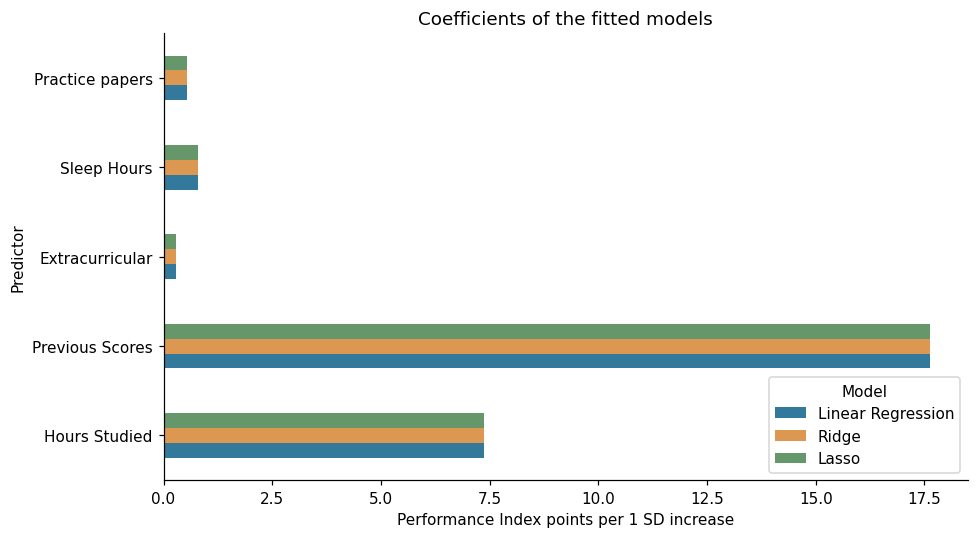

In [ ]:
standardized_coefficients = pd.DataFrame(
    {name: model.named_steps["model"].coef_ for name, model in models.items()}, index=feature_names)
original_coefficients = pd.DataFrame(index=feature_names)
intercepts = {}
for name, model in models.items():
    scaler, fitted = model.named_steps["scaler"], model.named_steps["model"]
    original_coefficients[name] = fitted.coef_ / scaler.scale_
    intercepts[name] = fitted.intercept_ - np.dot(fitted.coef_, scaler.mean_ / scaler.scale_)
    # Reconstructed original-unit predictions must match the fitted pipeline.
    assert np.allclose(X_test.to_numpy() @ original_coefficients[name].to_numpy() + intercepts[name],
                       predictions[name], atol=1e-8)
display(standardized_coefficients)
display(original_coefficients)
display(pd.Series(intercepts, name="Original-unit intercept").to_frame())
coefficient_effect = pd.DataFrame({
    "L2 coefficient norm": [np.linalg.norm(standardized_coefficients[n]) for n in models],
    "L1 coefficient norm": [np.abs(standardized_coefficients[n]).sum() for n in models],
    "Exact zero coefficients": [(standardized_coefficients[n] == 0).sum() for n in models]}, index=list(models))
display(coefficient_effect)
ax = standardized_coefficients.rename(index={"Sample Question Papers Practiced": "Practice papers",
                 "Extracurricular Activities": "Extracurricular"}).plot.barh(
    figsize=(9, 5), color=["#33799b", "#dc9851", "#66976b"])
ax.set(title="Coefficients of the fitted models", xlabel="Performance Index points per 1 SD increase", ylabel="Predictor")
ax.legend(title="Model", loc="lower right")
save_chart("01_coefficient_comparison.png")

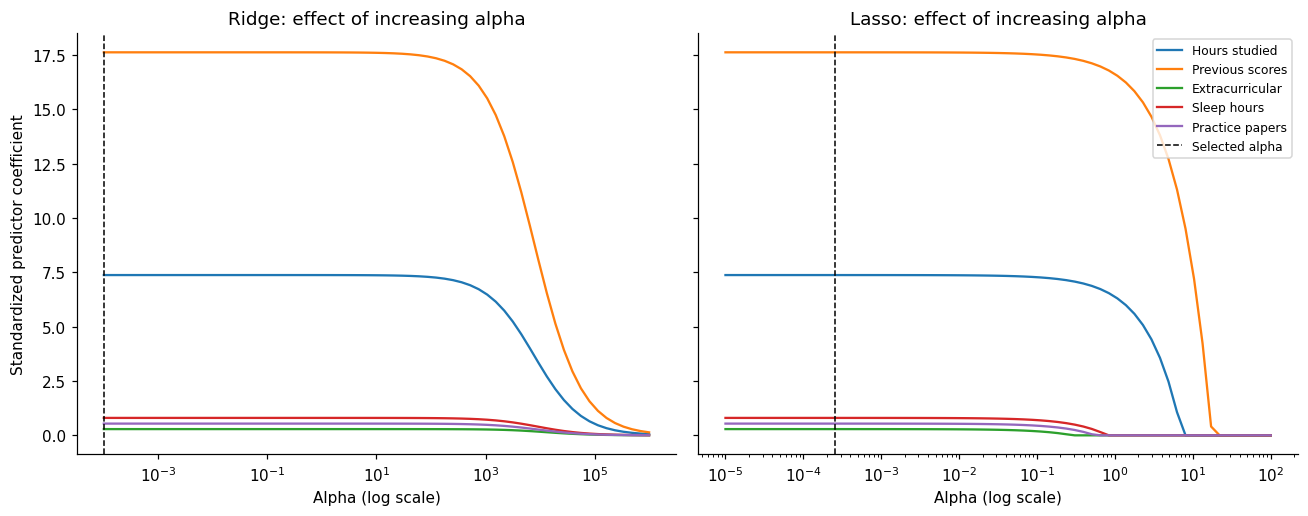

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
path_rows = []
short_names = ["Hours studied", "Previous scores", "Extracurricular", "Sleep hours", "Practice papers"]
for ax, name, grid in zip(axes, ["Ridge", "Lasso"], [np.logspace(-4, 6, 65), np.logspace(-5, 2, 65)]):
    path = []
    for alpha in grid:
        estimator = Ridge(alpha=alpha) if name == "Ridge" else Lasso(alpha=alpha, max_iter=50000, tol=1e-8)
        fitted = make_model(estimator).fit(X_train, y_train)
        coefs = fitted.named_steps["model"].coef_
        path.append(coefs)
        path_rows.append({"Model": name, "alpha": alpha, **dict(zip(feature_names, coefs))})
    ax.semilogx(grid, np.array(path))
    ax.axvline(cv_results.loc[name, "Selected alpha"], color="black", ls="--", lw=1)
    ax.set(title=f"{name}: effect of increasing alpha", xlabel="Alpha (log scale)")
axes[0].set_ylabel("Standardized predictor coefficient")
axes[1].legend(short_names + ["Selected alpha"], fontsize=8)
save_chart("02_regularization_paths.png")
pd.DataFrame(path_rows).to_csv(OUTPUT_DIR / "coefficient_paths.csv", index=False)

## 6. Prediction diagnostics

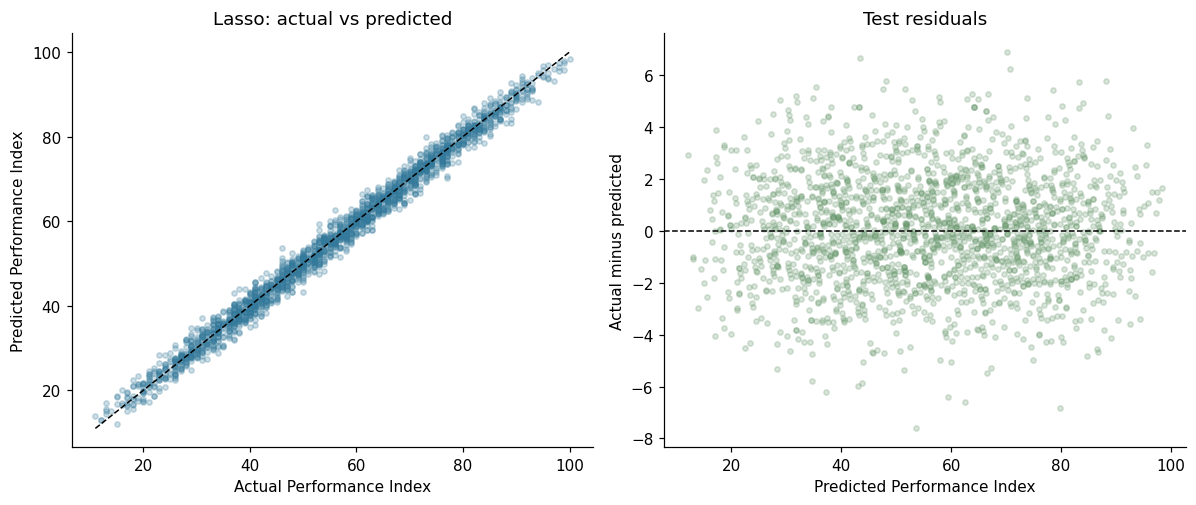

In [ ]:
pred = predictions[cv_choice]
residuals = y_test.to_numpy() - pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4.7))
axes[0].scatter(y_test, pred, alpha=0.25, s=12, color="#33799b")
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
axes[0].plot([lo, hi], [lo, hi], "k--", lw=1)
axes[0].set(title=f"{cv_choice}: actual vs predicted", xlabel="Actual Performance Index", ylabel="Predicted Performance Index")
axes[1].scatter(pred, residuals, alpha=0.25, s=12, color="#66976b")
axes[1].axhline(0, color="black", ls="--", lw=1)
axes[1].set(title="Test residuals", xlabel="Predicted Performance Index", ylabel="Actual minus predicted")
save_chart("03_prediction_diagnostics.png")

## 7. Conclusion (three sentences)

In [ ]:
best = comparison.loc[test_best]
rmse_spread = comparison["RMSE"].max() - comparison["RMSE"].min()
lasso_zeros = int(coefficient_effect.loc["Lasso", "Exact zero coefficients"])
conclusion = (
    f"{test_best} has the lowest held-out RMSE on this split ({best['RMSE']:.6f}) with R² = {best['R2']:.6f}, "
    f"while training-only cross-validation selects {cv_choice}. "
    f"The three test RMSEs span only {rmse_spread:.6f} Performance Index points, so this comparison offers "
    "little evidence of a meaningful generalization advantage; ordinary Linear Regression is a reasonable simpler choice. "
    f"Ridge applies L2 shrinkage and Lasso applies L1 shrinkage, but the selected penalties change the coefficients "
    f"only slightly and Lasso sets {lasso_zeros} of {len(feature_names)} coefficients to zero, "
    "indicating little benefit from regularization for this synthetic dataset."
)
print(conclusion)

Linear Regression has the lowest held-out RMSE on this split (2.075066) with R² = 0.988430, while training-only cross-validation selects Lasso. The three test RMSEs span only 0.000032 Performance Index points, so this comparison offers little evidence of a meaningful generalization advantage; ordinary Linear Regression is a reasonable simpler choice. Ridge applies L2 shrinkage and Lasso applies L1 shrinkage, but the selected penalties change the coefficients only slightly and Lasso sets 0 of 5 coefficients to zero, indicating little benefit from regularization for this synthetic dataset.


## 8. Save outputs and note limitations

In [ ]:
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv")
cv_results.to_csv(OUTPUT_DIR / "cross_validation_results.csv")
generalization.to_csv(OUTPUT_DIR / "train_test_rmse.csv")
standardized_coefficients.rename_axis("Feature").to_csv(OUTPUT_DIR / "coefficients_standardized.csv")
original_coefficients.rename_axis("Feature").to_csv(OUTPUT_DIR / "coefficients_original_units.csv")
pd.Series(intercepts, name="intercept").rename_axis("Model").to_csv(OUTPUT_DIR / "intercepts_original_units.csv")
coefficient_effect.to_csv(OUTPUT_DIR / "coefficient_shrinkage.csv")
pd.DataFrame({"Actual": y_test, **predictions}).rename_axis("source_row_index").to_csv(OUTPUT_DIR / "test_predictions.csv")
(OUTPUT_DIR / "conclusion.md").write_text("# Conclusion\n\n" + conclusion + "\n", encoding="utf-8")
assert comparison.shape == (3, 4) and np.isfinite(comparison.to_numpy()).all()
assert np.allclose(comparison["RMSE"] ** 2, comparison["MSE"])
assert all(len(pred) == len(y_test) for pred in predictions.values())
print("Saved comparison, coefficients, CV results, predictions, conclusion and three charts to", OUTPUT_DIR.resolve())

Saved comparison, coefficients, CV results, predictions, conclusion and three charts to /workspace/scratch/280081ade6a3/student-performance-regression/outputs


## **Best model and the effect of regularization**

Linear Regression achieved the lowest test RMSE of 2.0751 and an R² of 0.9884, making it a reasonable choice for this dataset. However, all three models performed almost identically, so the results do not demonstrate a meaningful difference in generalization. Ridge and Lasso slightly shrank the coefficients without improving test performance, and Lasso retained all five predictors.